# A4 Paper Detection with A* Search

Finds the four corners of an A4 sheet in a photo, even when a hand or arm partly covers it. Edges are found with Canny and Hough lines, line intersections become candidate corners, and the corners are chosen by searching that space with BFS, A* with an admissible heuristic (h1) and A* with a confidence-based heuristic (h2).

See the README for results and `docs/REPORT.md` for the full write-up.

## Imports

In [1]:
import os
import csv
import gc
import time
import heapq
import tracemalloc

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import hough_line, hough_line_peaks

## Detection functions

Scoring (`likelihoodA4`), candidate clustering, geometric checks, the search node, successor function, heuristics, the search itself, and image preprocessing.

In [2]:
target_height = 2800
target_width  = 2100

def likelihoodA4(rect, bw, weightA4Prior=0.3, neighborhood=0):
    if rect.shape != (4, 2):
        raise ValueError("rect should be 4x2 array with corners in (x,y) form.")

    image_height, image_width = bw.shape
    p_edge = 0.0

    for i in range(4):
        pt1 = rect[i]
        pt2 = rect[(i + 1) % 4]

        if np.allclose(pt1, pt2):
            return 0.0

        x1, y1 = pt1
        x2, y2 = pt2

        num_steps = int(2 * max(image_height, image_width))
        if num_steps < 1:
            num_steps = 1

        xs = np.linspace(x1, x2, num=num_steps, endpoint=True)
        ys = np.linspace(y1, y2, num=num_steps, endpoint=True)

        xs = np.rint(xs).astype(int)
        ys = np.rint(ys).astype(int)

        line_points = np.column_stack((ys, xs))
        line_points = np.unique(line_points, axis=0)

        if neighborhood > 0:
            expanded = []
            for (row, col) in line_points:
                if neighborhood == 1:
                    neighbors = [
                        (row, col),
                        (row + 1, col), (row - 1, col),
                        (row, col + 1), (row, col - 1)
                    ]
                else: 
                    neighbors = [
                        (row, col),
                        (row + 1, col),   (row - 1, col),
                        (row, col + 1),   (row, col - 1),
                        (row + 1, col+1), (row - 1, col+1),
                        (row + 1, col-1), (row - 1, col-1)
                    ]
                expanded.extend(neighbors)
            line_points = np.unique(np.array(expanded), axis=0)

        mask_in_bounds = (
            (line_points[:, 0] >= 0) & (line_points[:, 0] < image_height) &
            (line_points[:, 1] >= 0) & (line_points[:, 1] < image_width)
        )
        line_points = line_points[mask_in_bounds]

        if len(line_points) == 0:
            return 0.0

        edge_vals = bw[line_points[:, 0], line_points[:, 1]]
        fraction_on_edge = np.sum(edge_vals) / float(len(edge_vals))
        p_edge += fraction_on_edge

    p_edge /= 4.0

    v1 = rect[0] - rect[1]
    v2 = rect[1] - rect[2]
    v3 = rect[2] - rect[3]
    v4 = rect[3] - rect[0]

    normv1 = np.linalg.norm(v1)
    normv2 = np.linalg.norm(v2)
    normv3 = np.linalg.norm(v3)
    normv4 = np.linalg.norm(v4)

    if normv1 > normv2:
        ratio1 = normv1 / normv2
        ratio2 = normv3 / normv4
    else:
        ratio1 = normv2 / normv1
        ratio2 = normv4 / normv3

    ratio = (ratio1 + ratio2) / 2.0

    mu = 297.0 / 210.0
    sigma = 0.5
    q = np.exp(-(ratio - mu)**2 / (2 * sigma**2)) / (np.sqrt(2 * np.pi) * sigma)
    p = (1 - weightA4Prior) * p_edge + weightA4Prior * q
    
    return p

def cluster_points(pts, merge_dist=60):
    if not pts:
        return []
    pts_arr = np.array(pts)
    merged  = []
    used    = np.zeros(len(pts_arr), dtype=bool)

    for i in range(len(pts_arr)):
        if used[i]:
            continue
        dists   = np.abs(pts_arr[:, 0] - pts_arr[i, 0]) + np.abs(pts_arr[:, 1] - pts_arr[i, 1])
        cluster = np.where((dists < merge_dist) & (~used))[0]
        cx = int(np.mean(pts_arr[cluster, 0]))
        cy = int(np.mean(pts_arr[cluster, 1]))
        merged.append((cx, cy))
        used[cluster] = True

    return merged

def is_valid_angle(pts):
    p1 = np.array(pts[-3])
    p2 = np.array(pts[-2])
    p3 = np.array(pts[-1])
    v1 = p1 - p2
    v2 = p3 - p2
    len1 = np.linalg.norm(v1)
    len2 = np.linalg.norm(v2)
    
    if len1 < 18.0 or len2 < 18.0:
        return False
        
    cos_angle = np.clip(np.dot(v1, v2) / (len1 * len2), -1.0, 1.0)
    angle = np.degrees(np.arccos(cos_angle))
    return 75 <= angle <= 105

def is_valid_ratio(pts):
    sides = [np.linalg.norm(np.array(pts[(i+1)%4]) - np.array(pts[i])) for i in range(4)]
    if min(sides) < 175.0:
        return False

    opp1 = abs(sides[0] - sides[2]) / max(sides[0], sides[2])
    opp2 = abs(sides[1] - sides[3]) / max(sides[1], sides[3])
    if opp1 > 0.5 or opp2 > 0.5:
        return False

    ratio = max(sides[0], sides[1]) / min(sides[0], sides[1])
    return 0.8 <= ratio <= 2.2

def corners_span_image(pts, img_w, img_h):
    xs = [p[0] for p in pts]
    ys = [p[1] for p in pts]
    width_span  = max(xs) - min(xs)
    height_span = max(ys) - min(ys)
    return (width_span > img_w * 0.25) and (height_span > img_h * 0.25)

class SearchNode:
    def __init__(self, corners, g_cost, parent=None):
        self.corners = corners
        self.k       = len(corners)
        self.g_cost  = g_cost
        self.parent  = parent
        self.depth   = self.k
        
    def is_goal(self): 
        return self.k == 4
        
    def __lt__(self, other): 
        return self.g_cost < other.g_cost

def get_successors(current_node, all_pts, line_dict):
    successors = []

    if current_node.k == 0:
        for pt in all_pts:
            successors.append(SearchNode([pt], current_node.g_cost + 1, current_node))
        return successors

    first_corner = current_node.corners[0]
    first_score  = first_corner[0] + first_corner[1]
    last_pt = current_node.corners[-1]
    
    if last_pt not in line_dict:
        return successors

    line_tolerance = 88.0

    for entry in line_dict[last_pt]:
        for rho, theta in [(entry['rho1'], entry['theta1']),
                           (entry['rho2'], entry['theta2'])]:
            for pt in all_pts:
                if pt in current_node.corners:
                    continue
                
                if (pt[0] + pt[1]) < first_score:
                    continue
                    
                if abs(pt[0]*np.cos(theta) + pt[1]*np.sin(theta) - rho) >= line_tolerance:
                    continue

                new_corners = current_node.corners + [pt]
                penalty = 0.0

                if len(new_corners) >= 3:
                    p1 = np.array(new_corners[-3])
                    p2 = np.array(new_corners[-2])
                    p3 = np.array(new_corners[-1])
                    v1, v2 = p1 - p2, p3 - p2
                    len1, len2 = np.linalg.norm(v1), np.linalg.norm(v2)
                    
                    if len1 < 18.0 or len2 < 18.0:
                        continue
                        
                    cos_a = np.clip(np.dot(v1, v2) / (len1 * len2), -1.0, 1.0)
                    angle = np.degrees(np.arccos(cos_a))
                    
                    if not (75 <= angle <= 105):
                        continue
                        
                    penalty = abs(angle - 90.0) / 15.0

                if len(new_corners) == 4:
                    if not is_valid_ratio(new_corners):
                        continue
                    if not is_valid_angle([new_corners[2], new_corners[3], new_corners[0]]):
                        continue
                        
                    closed = False
                    if pt in line_dict:
                        for cl_entry in line_dict[pt]:
                            for cl_rho, cl_theta in [(cl_entry['rho1'], cl_entry['theta1']),
                                                     (cl_entry['rho2'], cl_entry['theta2'])]:
                                if abs(first_corner[0]*np.cos(cl_theta) +
                                       first_corner[1]*np.sin(cl_theta) - cl_rho) < line_tolerance:
                                    closed = True
                                    break
                            if closed:
                                break
                    if not closed:
                        continue

                successors.append(
                    SearchNode(new_corners, current_node.g_cost + 1 + penalty, current_node)
                )
                
    return successors

def h1(node):
    return 4 - node.k

def h2(node, edge_img):
    angle_conf = 0.5
    if node.k >= 3:
        p1 = np.array(node.corners[-3])
        p2 = np.array(node.corners[-2])
        p3 = np.array(node.corners[-1])
        v1, v2 = p1 - p2, p3 - p2
        len1, len2 = np.linalg.norm(v1), np.linalg.norm(v2)
        if len1 > 0 and len2 > 0:
            cos_a = np.clip(np.dot(v1, v2) / (len1 * len2), -1.0, 1.0)
            angle_conf = max(0.0, 1.0 - abs(90.0 - np.degrees(np.arccos(cos_a))) / 15.0)

    edge_conf = 0.0
    if node.k >= 1:
        cx, cy = node.corners[-1]
        h_img, w_img = edge_img.shape
        patch_r = 35
        patch = edge_img[max(0, cy-patch_r):min(h_img, cy+patch_r),
                         max(0, cx-patch_r):min(w_img, cx+patch_r)]
        if patch.size > 0:
            edge_conf = np.sum(patch > 0) / float(patch.size)

    return (4 - node.k) * (1.0 - (0.8 * angle_conf + 0.2 * edge_conf))

def run_search(all_pts, line_dict, edge_img, mode="h1", max_nodes=20000):
    gc.collect()
    tracemalloc.start()
    start_time = time.time()

    img_h, img_w = edge_img.shape
    start_node   = SearchNode([], g_cost=0)
    pq, tie_break = [], 0

    def compute_f(n):
        if mode == "bfs": return n.g_cost
        return n.g_cost + (h2(n, edge_img) if mode == "h2" else h1(n))

    heapq.heappush(pq, (compute_f(start_node), tie_break, start_node))

    visited          = set()
    nodes_expanded   = 0
    best_result_node = None
    best_score       = -1.0

    while pq and nodes_expanded < max_nodes:
        _, _, current = heapq.heappop(pq)
        state_key = frozenset(current.corners)
        
        if state_key in visited:
            continue
            
        visited.add(state_key)
        nodes_expanded += 1

        if current.is_goal():
            if not corners_span_image(current.corners, img_w, img_h):
                continue
                
            score = likelihoodA4(np.array(current.corners, dtype=float), edge_img > 0)
            
            if score > best_score:
                best_score, best_result_node = score, current
                
            if score >= 0.40:
                break
            continue

        for child in get_successors(current, all_pts, line_dict):
            child_key = frozenset(child.corners)
            if child_key not in visited:
                tie_break += 1
                heapq.heappush(pq, (compute_f(child), tie_break, child))

    elapsed = time.time() - start_time
    _, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    return {
        'corners'   : best_result_node.corners if best_result_node else None,
        'score'     : best_score,
        'nodes'     : nodes_expanded,
        'time'      : elapsed,
        'depth'     : best_result_node.depth if best_result_node else 0,
        'memory_kb' : peak_mem / 1024
    }

def preprocess_image(filepath):
    img = cv2.imread(filepath)
    if img is None:
        raise IOError(f"ERROR: Image not found at '{filepath}'")

    if img.shape[0] < img.shape[1]:
        img = np.rot90(img, k=3)

    img  = cv2.resize(img, (target_width, target_height), interpolation=cv2.INTER_AREA)
    grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blurred = cv2.GaussianBlur(grey, (7, 7), 0)
    edged   = cv2.Canny(blurred, 50, 150)
    binary  = cv2.dilate(edged, np.ones((5, 5), np.uint8), iterations=1)

    return grey, binary

def find_hough_lines(binary):
    tested_angles = np.deg2rad(np.arange(-90, 90, 0.5))
    hspace, angles, dists = hough_line(binary > 0, theta=tested_angles)

    _, theta_peaks, dist_peaks = hough_line_peaks(
        hspace, angles, dists,
        num_peaks=25,
        threshold=0.25 * np.max(hspace)
    )

    if len(theta_peaks) == 0:
        return theta_peaks, dist_peaks

    angle_degs = np.rad2deg(theta_peaks)
    best_count = 0
    best_angle = 0

    for ref_angle in angle_degs:
        count = 0
        for a in angle_degs:
            diff = abs(a - ref_angle) % 180
            if diff < 15 or diff > 165:
                count += 1
        if count > best_count:
            best_count = count
            best_angle = ref_angle

    keep = []
    for a in angle_degs:
        diff = abs(a - best_angle) % 180
        is_parallel = (diff < 20) or (diff > 160)
        diff_perp = abs(diff - 90)
        is_perpendicular = (diff_perp < 20)
        keep.append(is_parallel or is_perpendicular)

    keep = np.array(keep)
    if not np.any(keep):
        return theta_peaks, dist_peaks

    return theta_peaks[keep], dist_peaks[keep]

def find_intersections(theta_peaks, dist_peaks, img_height, img_width):
    intersection_list = []
    line_dict = {}

    for i in range(len(dist_peaks)):
        for j in range(i + 1, len(dist_peaks)):
            if np.isclose(theta_peaks[i], theta_peaks[j], atol=1e-6):
                continue

            angle_diff = abs(np.rad2deg(theta_peaks[i]) - np.rad2deg(theta_peaks[j]))
            angle_diff = min(angle_diff, 180 - angle_diff)
            
            if angle_diff < 50 or angle_diff > 130:
                continue

            A = np.array([[np.cos(theta_peaks[i]), np.sin(theta_peaks[i])],
                          [np.cos(theta_peaks[j]), np.sin(theta_peaks[j])]])
            b = np.array([dist_peaks[i], dist_peaks[j]])
            
            try:
                x, y = np.linalg.solve(A, b)
            except np.linalg.LinAlgError:
                continue

            if not (img_width * 0.02 < x < img_width * 0.98):
                continue
            if not (img_height * 0.02 < y < img_height * 0.98):
                continue

            pt = (int(round(x)), int(round(y)))
            entry = {
                'rho1': dist_peaks[i], 'theta1': theta_peaks[i],
                'rho2': dist_peaks[j], 'theta2': theta_peaks[j],
                'x': pt[0], 'y': pt[1]
            }
            intersection_list.append(entry)
            line_dict.setdefault(pt, []).append(entry)

    raw_pts    = list(set((it['x'], it['y']) for it in intersection_list))
    unique_pts = cluster_points(raw_pts, merge_dist=60)

    clustered_dict = {}
    if unique_pts:
        clust_arr = np.array(unique_pts)
        for entry in intersection_list:
            old_pt = (entry['x'], entry['y'])
            dists  = np.abs(clust_arr[:,0] - old_pt[0]) + np.abs(clust_arr[:,1] - old_pt[1])
            nearest = unique_pts[int(np.argmin(dists))]
            clustered_dict.setdefault(nearest, []).append(entry)

    return unique_pts, clustered_dict

def detect_a4_main(filepath):
    grey, binary = preprocess_image(filepath)
    theta_peaks, dist_peaks = find_hough_lines(binary)
    unique_pts, line_dict   = find_intersections(
        theta_peaks, dist_peaks, grey.shape[0], grey.shape[1]
    )

    print(f"\nProcessing : {os.path.basename(filepath)}")
    print(f"Candidates : {len(unique_pts)}")

    if not unique_pts or len(unique_pts) < 4:
        print("Not enough intersection points found.")
        return False, np.zeros((4, 2)), 0.0, 0.0

    print("Running BFS...")
    res_bfs = run_search(unique_pts, line_dict, binary, mode="bfs", max_nodes=50000)

    print("Running A* (h1)...")
    res_h1  = run_search(unique_pts, line_dict, binary, mode="h1", max_nodes=20000)

    print("Running A* (h2)...")
    res_h2  = run_search(unique_pts, line_dict, binary, mode="h2", max_nodes=20000)

    print(f"\n{'Method':<10} {'Score':>6}  {'Nodes':>6}  {'Time(s)':>7}  {'Depth':>5}  {'Mem(KB)':>8}")
    print("-" * 55)
    for lbl, res in [("BFS", res_bfs), ("A* h1", res_h1), ("A* h2", res_h2)]:
        if res['corners'] is not None:
            print(f"{lbl:<10} {res['score']:>6.3f}  {res['nodes']:>6d}  "
                  f"{res['time']:>7.2f}  {res['depth']:>5d}  {res['memory_kb']:>8.1f}")
        else:
            print(f"{lbl:<10} {'N/A':>6}  {res['nodes']:>6d}  "
                  f"{res['time']:>7.2f}  {'N/A':>5}  {res['memory_kb']:>8.1f}")

    best  = max([res_bfs, res_h1, res_h2], key=lambda r: r['score'])
    found = (best['score'] >= 0.20) and (best['corners'] is not None)

    average_ratio = 0.0
    if found:
        c     = np.array(best['corners'], dtype=float)
        sides = [np.linalg.norm(c[i] - c[(i+1)%4]) for i in range(4)]
        average_ratio = sum([max(sides)/29.7, min(sides)/21.0]) / 2.0

    print(f"\nResult: Found={found} | Score={best['score']:.3f} | Ratio={average_ratio:.3f} px/cm\n")

    final_corners = np.array(best['corners'], dtype=float) if best['corners'] else np.zeros((4, 2))
    return found, final_corners, best['score'], average_ratio

def draw_a4_rectangle(image, corners, color=(0, 0, 255), thickness=2):
    """
    Draws lines between 4 corners (in an Nx2 array) on the given image.
    Assumes 'corners' are in (x, y) order in the same coordinate system as 'image'.
    """
    num_corners = corners.shape[0]
    for i in range(num_corners):
        x1, y1 = corners[i]
        x2, y2 = corners[(i + 1) % num_corners]
        cv2.line(image,
                 (int(x1), int(y1)),
                 (int(x2), int(y2)),
                 color, thickness)

## Batch processing

Runs all three search methods on every image in `images/`, saves the results to `results/a4_detection_results.csv` and draws the best outline on each image.

In [3]:
input_folder = "images"

output_folder = "results"
os.makedirs(output_folder, exist_ok=True)

csv_path = os.path.join(output_folder, "a4_detection_results.csv")

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

with open(csv_path, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)

    writer.writerow([
        "Filename", "Found", "BestScore", "AvgRatio",
        "Corner1_x", "Corner1_y",
        "Corner2_x", "Corner2_y",
        "Corner3_x", "Corner3_y",
        "Corner4_x", "Corner4_y",
    ])

    for filename in sorted(os.listdir(input_folder)):
        ext = os.path.splitext(filename)[1].lower()
        if ext not in valid_extensions:
            continue

        img_path = os.path.join(input_folder, filename)
        print(f"Processing: {img_path}")

        found, bestA4, bestScore, avg_ratio = detect_a4_main(img_path)

        if found:
            c1x, c1y = bestA4[0]
            c2x, c2y = bestA4[1]
            c3x, c3y = bestA4[2]
            c4x, c4y = bestA4[3]
            row_data = [
                filename, found, f"{bestScore:.3f}", f"{avg_ratio:.3f}",
                f"{c1x:.1f}", f"{c1y:.1f}",
                f"{c2x:.1f}", f"{c2y:.1f}",
                f"{c3x:.1f}", f"{c3y:.1f}",
                f"{c4x:.1f}", f"{c4y:.1f}",
            ]
        else:
            row_data = [filename, found, "", "", "", "", "", "", "", "", "", ""]

        writer.writerow(row_data)

        if found:
            image_for_overlay = cv2.imread(img_path)

            if image_for_overlay is not None:
                if image_for_overlay.shape[0] < image_for_overlay.shape[1]:
                    image_for_overlay = np.rot90(image_for_overlay, k=3)

                overlay_img = cv2.resize(image_for_overlay,
                                        (target_width, target_height),
                                        interpolation=cv2.INTER_AREA)

                draw_a4_rectangle(overlay_img, bestA4, color=(0, 0, 255), thickness=8)

                out_path = os.path.join(
                    output_folder,
                    f"{os.path.splitext(filename)[0]}_overlay.jpg"
                )
                cv2.imwrite(out_path, overlay_img)

        print("Done.\n")

print(f"\nBatch complete!")
print(f"CSV saved to: {csv_path}")
print(f"Annotated images saved to: {output_folder}")

Processing: images/photo_1.jpg



Processing : photo_1.jpg
Candidates : 24
Running BFS...


Running A* (h1)...


Running A* (h2)...



Method      Score   Nodes  Time(s)  Depth   Mem(KB)
-------------------------------------------------------
BFS         0.412     799     8.46      4    8008.1
A* h1       0.412     216     1.41      4    7780.4
A* h2       0.412     706     9.00      4    8334.7

Result: Found=True | Score=0.412 | Ratio=46.673 px/cm

Done.

Processing: images/photo_2.jpg


...


Method      Score   Nodes  Time(s)  Depth   Mem(KB)
-------------------------------------------------------
BFS         0.476     813     3.60      4    6742.6
A* h1       0.476     230     0.86      4    6934.6
A* h2       0.476     722     3.50      4    6920.5

Result: Found=True | Score=0.476 | Ratio=54.640 px/cm

Done.

Processing: images/photo_5.jpg



Processing : photo_5.jpg
Candidates : 49
Running BFS...


Running A* (h1)...


Running A* (h2)...



Method      Score   Nodes  Time(s)  Depth   Mem(KB)
-------------------------------------------------------
BFS         0.613    3715    25.34      4   10278.2
A* h1       0.613     712     4.12      4    9753.1
A* h2       0.613    3144    23.61      4   10517.8

Result: Found=True | Score=0.613 | Ratio=40.696 px/cm

Done.


Batch complete!
CSV saved to: results/a4_detection_results.csv
Annotated images saved to: results


## Results

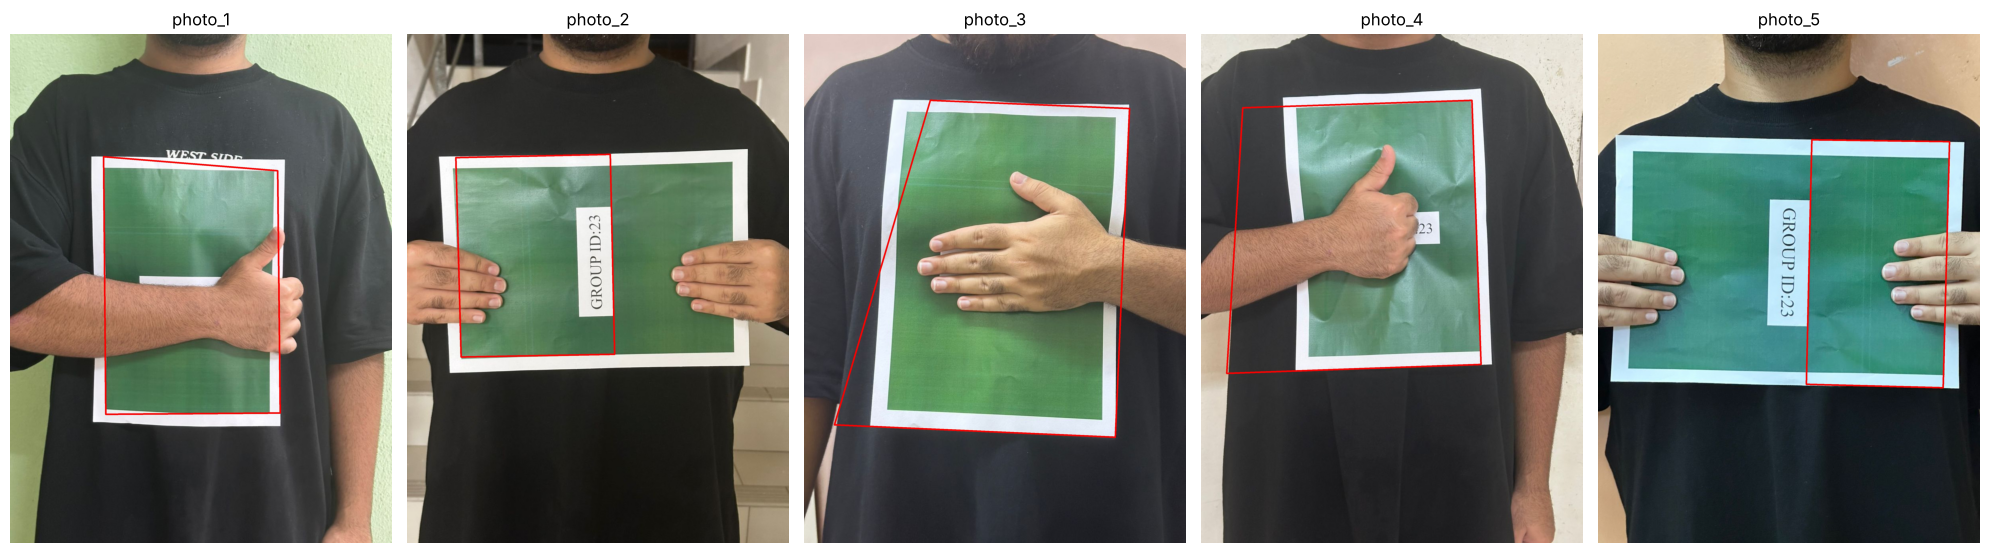

In [4]:
# Show the detected A4 outlines
overlays = sorted(f for f in os.listdir(output_folder) if f.endswith("_overlay.jpg"))
fig, axes = plt.subplots(1, len(overlays), figsize=(4 * len(overlays), 6))
for ax, name in zip(np.atleast_1d(axes), overlays):
    ax.imshow(cv2.cvtColor(cv2.imread(os.path.join(output_folder, name)), cv2.COLOR_BGR2RGB))
    ax.set_title(name.replace("_overlay.jpg", ""))
    ax.axis("off")
plt.tight_layout()
plt.show()